# Bank Customer Behaviour Analysis

## 1. Project Title
Bank Customer Behaviour Analysis

## 2. Problem Statement
This project analyzes bank customer data to understand customer behaviour and identify patterns associated with customer exit.

## 3. Objectives
- Clean and analyse customer data.
- Perform EDA and feature engineering.
- Identify customer behaviour and exit patterns.
- Perform customer segmentation where suitable.
- Develop business insights and recommendations.

## 4. Dataset
The project uses `bank_churn_dataset.csv`, containing 80,000 rows and 26 columns.

## 5. Methodology / Project Workflow
Data Collection → Data Cleaning → EDA → Feature Engineering → RFM Analysis → Customer Segmentation → Product & Revenue Analysis → Strategic Priority Score → Business Recommendations.

*RFM and product/revenue analysis will be limited to the information available in the dataset.*

## 6. Tools & Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Jupyter Notebook and GitHub.

In [25]:

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path(
    r"C:\Users\Lenovo\Desktop\Bank_Customer_Behaviour_Analysis\Data\bank_churn_dataset.csv"
)

df_raw = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df_raw.shape)

print("\nColumn Names:")
print(df_raw.columns.tolist())

print("\nData Types:")
print(df_raw.dtypes)

print("\nMissing Values:")
print(df_raw.isnull().sum())

print("\nDuplicate Rows:", df_raw.duplicated().sum())

print("\nFirst 5 Rows:")
display(df_raw.head())


Dataset Shape: (80000, 26)

Column Names:
['id', 'full_name', 'credit_sco', 'gender', 'age', 'occupation', 'balance', 'monthly_ir', 'address', 'origin_province', 'tenure_ye', 'married', 'nums_card', 'nums_service', 'active_member', 'last_active_date', 'last_transaction_month', 'created_date', 'exit', 'customer_segment', 'engagement_score', 'loyalty_level', 'digital_behavior', 'risk_score', 'risk_segment', 'cluster_group']

Data Types:
id                          int64
full_name                     str
credit_sco                  int64
gender                        str
age                         int64
occupation                    str
balance                     int64
monthly_ir                  int64
address                       str
origin_province               str
tenure_ye                   int64
married                     int64
nums_card                   int64
nums_service                int64
active_member                bool
last_active_date              str
last_transaction_

,id,full_name,credit_sco,gender,age,occupation,balance,monthly_ir,address,origin_province,...,last_transaction_month,created_date,exit,customer_segment,engagement_score,loyalty_level,digital_behavior,risk_score,risk_segment,cluster_group
0,1,Đặng Văn Vũ,725,male,55,Chủ Doanh nghiệp nhỏ,177306004,121000000,Phường An Hội (BT),TP. Hồ Chí Minh,...,91038993,27/02/2025,False,Priority,90,Bronze,mobile,0.0359,Low,4
1,2,Bùi Hữu Phúc,689,male,45,Nội trợ/Sinh viên,1927416,5000000,Phường Bến Thành (Q1),Đồng Nai,...,3255569,29/07/2021,False,Mass,63,Gold,mobile,0.2664,Low,2
2,3,Lê Văn Mai,702,female,44,Chủ Doanh nghiệp nhỏ,304931745,109000000,Phường Hòa Bình (Q11),TP. Hồ Chí Minh,...,0,03/03/2021,False,Priority,36,Silver,offline,0.1343,Low,4
3,4,Dương Trần Nhiên,766,male,44,Chủ Doanh nghiệp nhỏ,50615501,79000000,Phường 7 (Q7),TP. Hồ Chí Minh,...,0,12/02/2022,False,Priority,23,Bronze,offline,0.2185,Low,4
4,5,Dương Thu Linh,677,female,77,Giáo viên/Giảng viên,40532432,25000000,Phường Thắng Lợi (Q10),TP. Hồ Chí Minh,...,0,24/07/2022,False,Emerging,23,Bronze,offline,0.2942,Low,2


## 2. Data Understanding

This section examines the dataset structure, customer attributes, data types, and overall data quality before analysis.

In [26]:
print("Dataset Information:")
df_raw.info()

print("\nStatistical Summary:")
display(df_raw.describe(include="all").T)

print("\nUnique Values:")
display(df_raw.nunique().sort_values(ascending=False))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      80000 non-null  int64  
 1   full_name               80000 non-null  str    
 2   credit_sco              80000 non-null  int64  
 3   gender                  80000 non-null  str    
 4   age                     80000 non-null  int64  
 5   occupation              80000 non-null  str    
 6   balance                 80000 non-null  int64  
 7   monthly_ir              80000 non-null  int64  
 8   address                 80000 non-null  str    
 9   origin_province         80000 non-null  str    
 10  tenure_ye               80000 non-null  int64  
 11  married                 80000 non-null  int64  
 12  nums_card               80000 non-null  int64  
 13  nums_service            80000 non-null  int64  
 14  active_member           8000

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,80000.0,NaN,NaN,NaN,40000.5,23094.155105,1.0,20000.75,40000.5,60000.25,80000.0
full_name,80000,5100,Lê Minh Quang,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_sco,80000.0,NaN,NaN,NaN,684.321137,51.169733,495.0,649.0,682.0,718.0,800.0
gender,80000,2,male,40008,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,80000.0,NaN,NaN,NaN,49.381862,15.06748,20.0,38.0,47.0,58.0,90.0
occupation,80000,10,Kỹ sư/Chuyên viên IT,8199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,80000.0,NaN,NaN,NaN,61183195.39705,88686198.425266,408663.0,14625918.25,30902758.0,69609941.25,1000000000.0
monthly_ir,80000.0,NaN,NaN,NaN,37788200.0,36551066.202171,3000000.0,14000000.0,23000000.0,47000000.0,216000000.0
address,80000,16,Linh Trung (TP Thủ Đức),5085,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_province,80000,9,TP. Hồ Chí Minh,40148,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Unique Values:


id                        80000
balance                   79920
last_transaction_month    17132
full_name                  5100
risk_score                 4630
created_date               1643
last_active_date           1614
credit_sco                  291
monthly_ir                  209
engagement_score             83
age                          71
address                      16
occupation                   10
origin_province               9
nums_service                  8
tenure_ye                     5
nums_card                     5
cluster_group                 4
customer_segment              4
married                       4
loyalty_level                 3
gender                        2
active_member                 2
exit                          2
digital_behavior              2
risk_segment                  2
dtype: int64

## 3. Data Quality Assessment

This section checks missing values, duplicate records, and potential data quality issues.

In [27]:
quality_report = pd.DataFrame({
    "Data Type": df_raw.dtypes.astype(str),
    "Missing Values": df_raw.isnull().sum(),
    "Missing Percentage": (df_raw.isnull().mean() * 100).round(2),
    "Unique Values": df_raw.nunique()
})

display(quality_report)
print("Duplicate Rows:", df_raw.duplicated().sum())

,Data Type,Missing Values,Missing Percentage,Unique Values
id,int64,0,0.0,80000
full_name,str,0,0.0,5100
credit_sco,int64,0,0.0,291
gender,str,0,0.0,2
age,int64,0,0.0,71
occupation,str,0,0.0,10
balance,int64,0,0.0,79920
monthly_ir,int64,0,0.0,209
address,str,0,0.0,16
origin_province,str,0,0.0,9


Duplicate Rows: 0


## 4. Data Cleaning and Preparation

The original dataset is preserved. A working copy is created for analysis, and data quality issues are investigated before making changes.

In [28]:
df = df_raw.copy()

print("Original Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())

print("\nDate-Like Columns:")
print([col for col in df.columns if "date" in col.lower()])

print("\nNumerical Summary:")
display(df.select_dtypes(include=np.number).describe().T)

Original Shape: (80000, 26)
Duplicate Rows: 0
Missing Values: 0

Date-Like Columns:
['last_active_date', 'created_date']

Numerical Summary:


,count,mean,std,min,25%,50%,75%,max
id,80000.0,4.000050e+04,2.309416e+04,1.000000e+00,2.000075e+04,4.000050e+04,6.000025e+04,8.000000e+04
credit_sco,80000.0,6.843211e+02,5.116973e+01,4.950000e+02,6.490000e+02,6.820000e+02,7.180000e+02,8.000000e+02
age,80000.0,4.938186e+01,1.506748e+01,2.000000e+01,3.800000e+01,4.700000e+01,5.800000e+01,9.000000e+01
balance,80000.0,6.118320e+07,8.868620e+07,4.086630e+05,1.462592e+07,3.090276e+07,6.960994e+07,1.000000e+09
monthly_ir,80000.0,3.778820e+07,3.655107e+07,3.000000e+06,1.400000e+07,2.300000e+07,4.700000e+07,2.160000e+08
tenure_ye,80000.0,1.777250e+00,1.315828e+00,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00
married,80000.0,9.708250e-01,6.946977e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,3.000000e+00
nums_card,80000.0,2.634688e+00,1.218556e+00,1.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00
nums_service,80000.0,3.564425e+00,2.002448e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00,8.000000e+00
last_transaction_month,80000.0,8.831755e+06,3.378683e+07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.000000e+08


## 5. Analytical Dataset Preparation

This section prepares a working dataset and excludes direct personal identifiers from analytical features.

In [29]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove personal identifiers from the analytical dataset
identifier_columns = [
    col for col in df.columns
    if col.lower() in [
        "id", "full_name", "name", "address", "email", "phone"
    ]
]

df = df.drop(columns=identifier_columns, errors="ignore")

print("Dataset shape after preparation:", df.shape)
print("Remaining personal identifier columns:", [
    col for col in df.columns
    if col.lower() in [
        "id", "full_name", "name", "address", "email", "phone"
    ]
])

Dataset shape after preparation: (80000, 23)
Remaining personal identifier columns: []


## 6. Numerical and Categorical Analysis

Numerical and categorical variables are summarized separately to understand customer characteristics.

In [30]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

if numerical_columns:
    display(df[numerical_columns].describe().T)

for col in categorical_columns:
    print(f"\n{col} — Value Counts")
    display(df[col].value_counts(dropna=False).head(20))

Numerical Columns:
['credit_sco', 'age', 'balance', 'monthly_ir', 'tenure_ye', 'married', 'nums_card', 'nums_service', 'last_transaction_month', 'engagement_score', 'risk_score', 'cluster_group']

Categorical Columns:
['gender', 'occupation', 'origin_province', 'active_member', 'last_active_date', 'created_date', 'exit', 'customer_segment', 'loyalty_level', 'digital_behavior', 'risk_segment']


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7404\230610474.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


,count,mean,std,min,25%,50%,75%,max
credit_sco,80000.0,6.843211e+02,5.116973e+01,4.950000e+02,6.490000e+02,6.820000e+02,7.180000e+02,8.000000e+02
age,80000.0,4.938186e+01,1.506748e+01,2.000000e+01,3.800000e+01,4.700000e+01,5.800000e+01,9.000000e+01
balance,80000.0,6.118320e+07,8.868620e+07,4.086630e+05,1.462592e+07,3.090276e+07,6.960994e+07,1.000000e+09
monthly_ir,80000.0,3.778820e+07,3.655107e+07,3.000000e+06,1.400000e+07,2.300000e+07,4.700000e+07,2.160000e+08
tenure_ye,80000.0,1.777250e+00,1.315828e+00,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00
married,80000.0,9.708250e-01,6.946977e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,3.000000e+00
nums_card,80000.0,2.634688e+00,1.218556e+00,1.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00
nums_service,80000.0,3.564425e+00,2.002448e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00,8.000000e+00
last_transaction_month,80000.0,8.831755e+06,3.378683e+07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,6.000000e+08
engagement_score,80000.0,3.172540e+01,2.347486e+01,7.000000e+00,1.600000e+01,2.200000e+01,3.800000e+01,1.000000e+02



gender — Value Counts


gender
male      40008
female    39992
Name: count, dtype: int64

...

loyalty_level
Bronze    69252
Silver     8977
Gold       1771
Name: count, dtype: int64


digital_behavior — Value Counts


digital_behavior
offline    62824
mobile     17176
Name: count, dtype: int64


risk_segment — Value Counts


risk_segment
Low       74753
Medium     5247
Name: count, dtype: int64

## 7. Exploratory Data Analysis

This section explores customer demographics, account characteristics, engagement, and other available variables using visualizations.

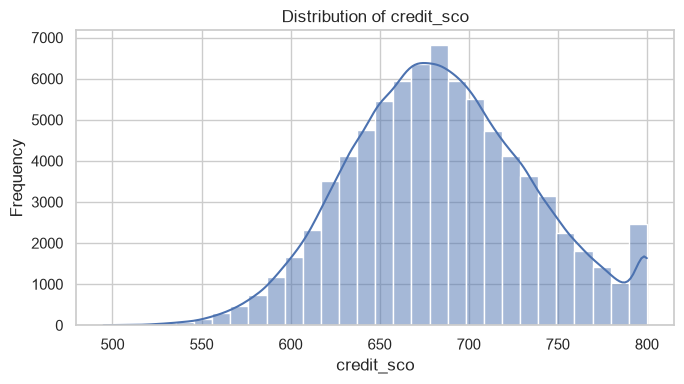

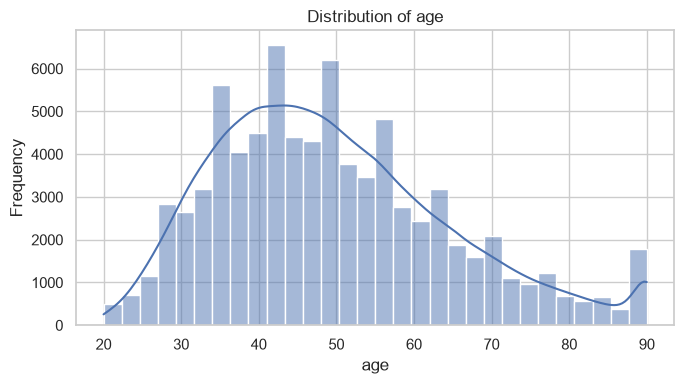

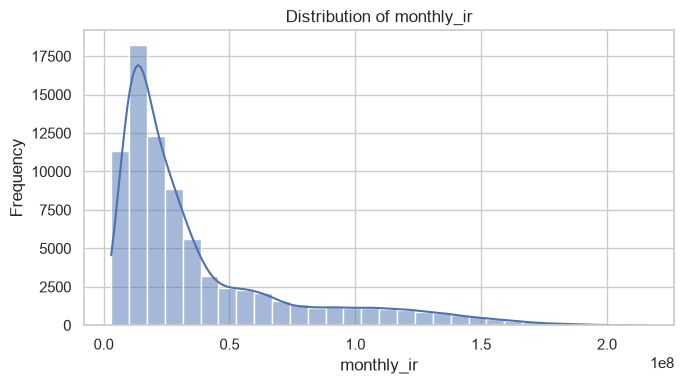

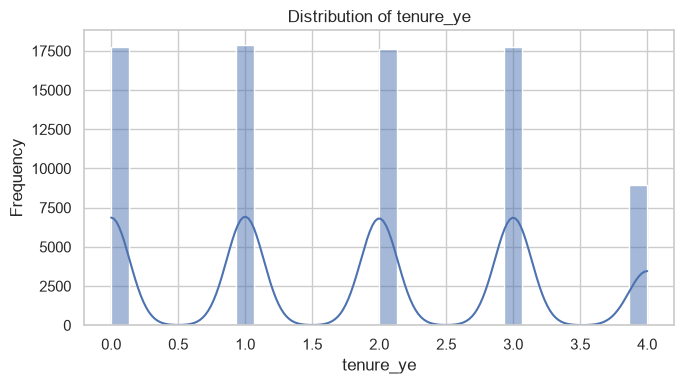

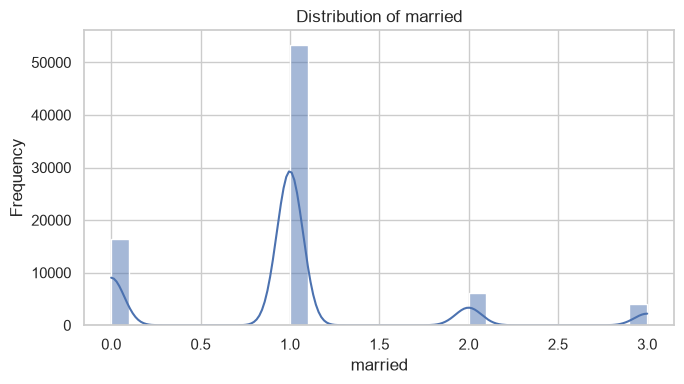

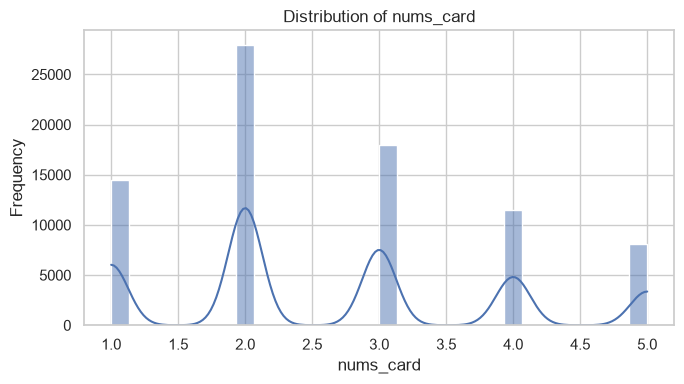

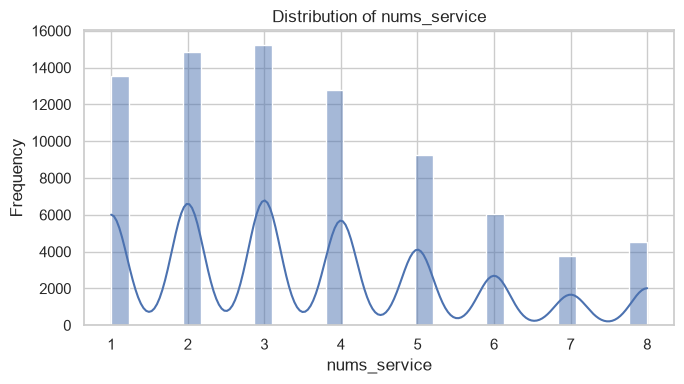

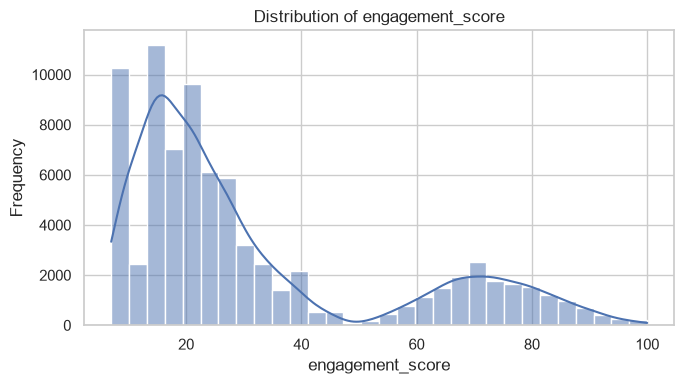

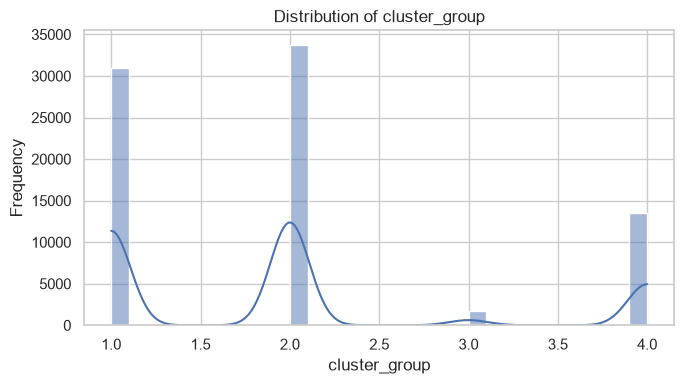

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plot_columns = [
    col for col in numerical_columns
    if df[col].nunique() > 1
    and df[col].nunique() <= 1000
]

for col in plot_columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col].dropna(), bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

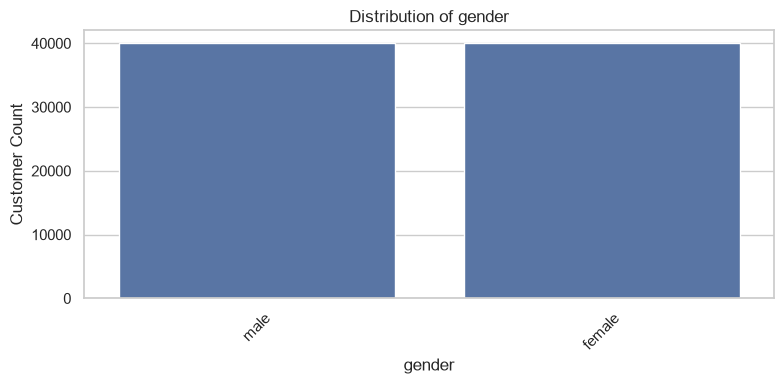

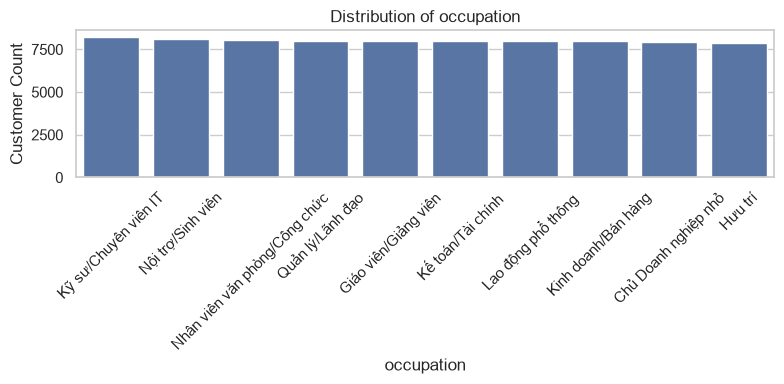

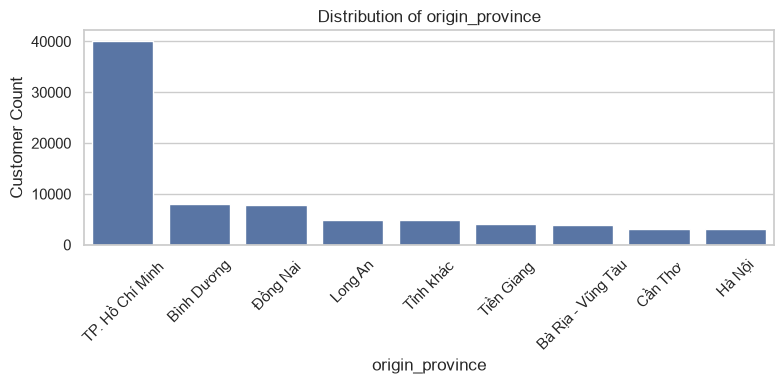

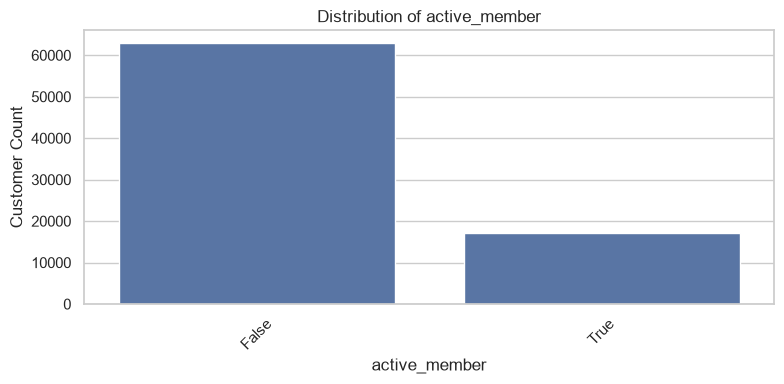

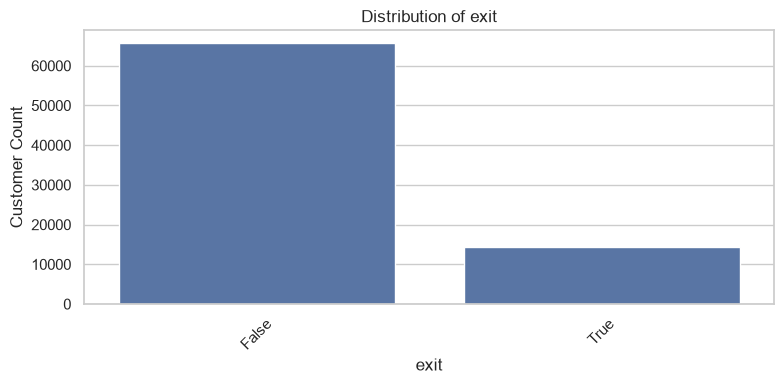

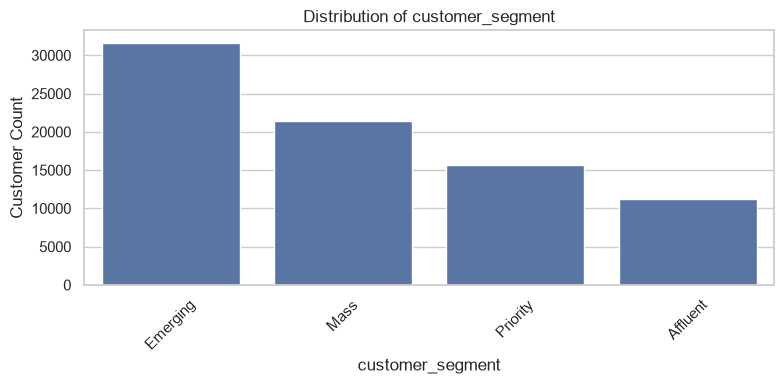

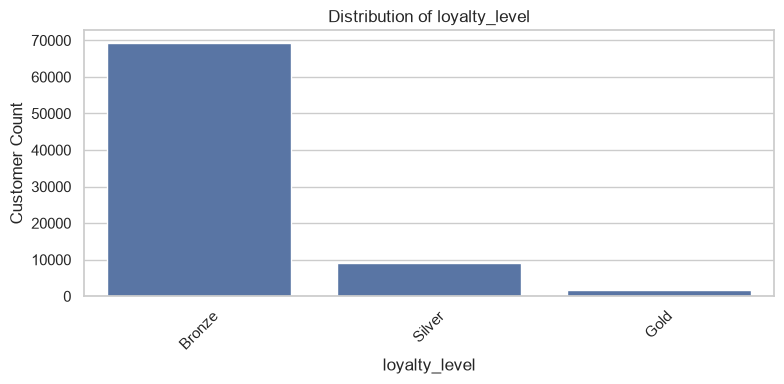

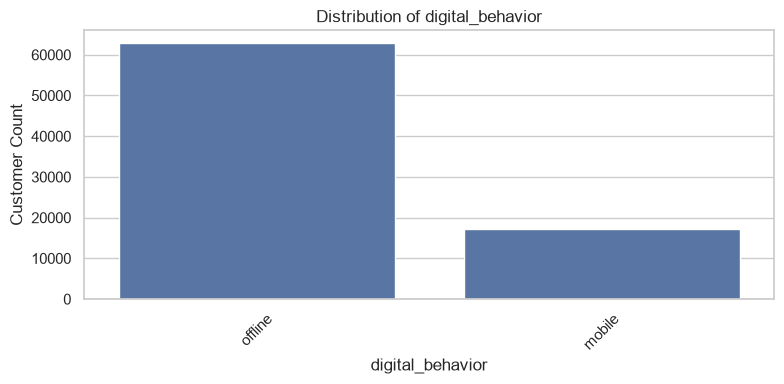

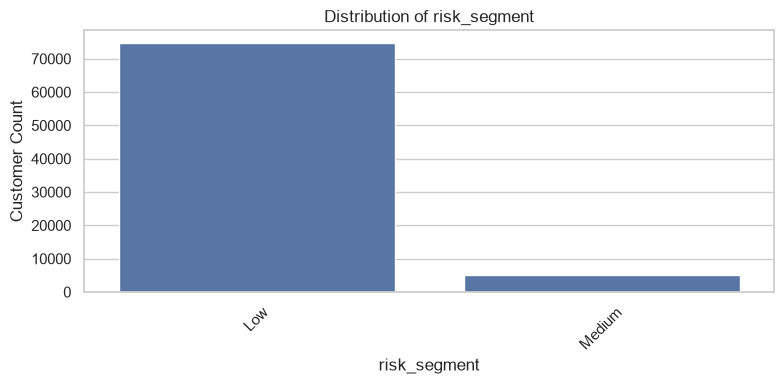

In [32]:
for col in categorical_columns:
    if df[col].nunique(dropna=False) <= 20:
        plt.figure(figsize=(8, 4))
        order = df[col].value_counts().index
        sns.countplot(data=df, x=col, order=order)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Customer Count")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

## 8. Correlation Analysis

Correlation analysis examines relationships between numerical variables. Correlation does not establish causation.

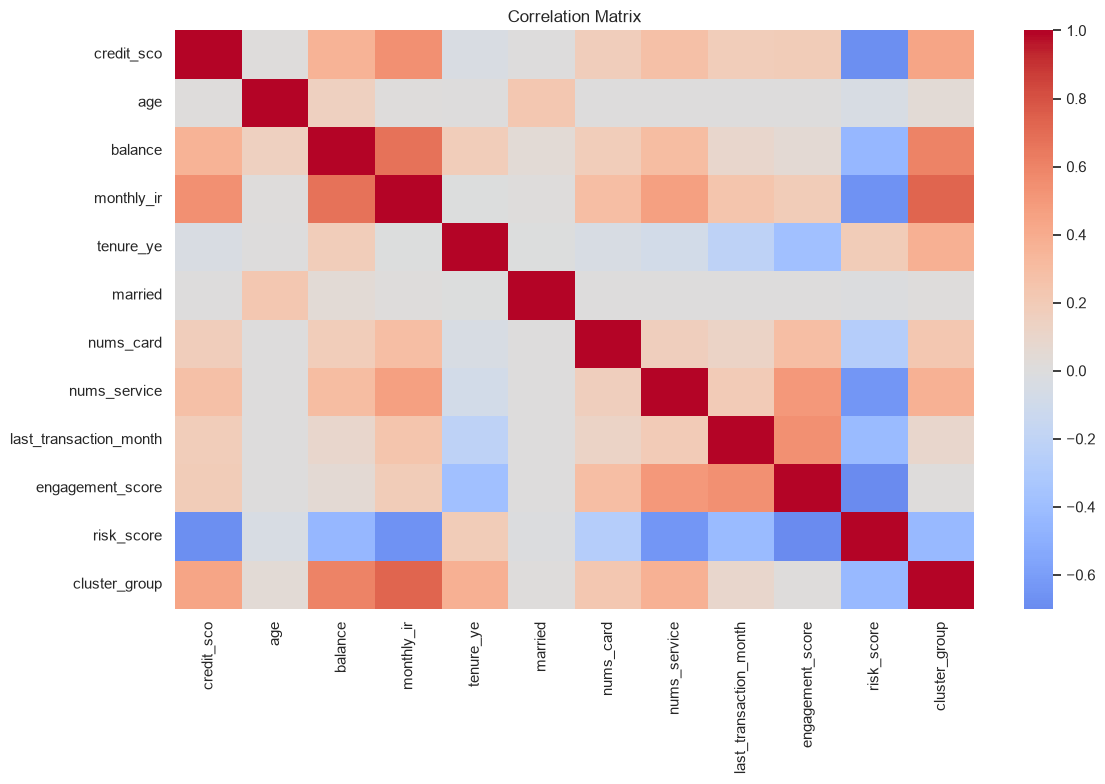

In [33]:
corr_df = df.select_dtypes(include=np.number)
corr_df = corr_df.loc[:, corr_df.nunique() > 1]

if corr_df.shape[1] >= 2:
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        corr_df.corr(),
        annot=False,
        cmap="coolwarm",
        center=0
    )
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough varying numerical columns for correlation analysis.")

## 9. Customer Churn Analysis

This section examines the available churn indicator and compares churn across suitable customer characteristics.

In [34]:
churn_candidates = [
    col for col in df.columns
    if col.lower() in ["exit", "churn", "churned", "churn_status"]
]

print("Possible Churn Columns:", churn_candidates)

Possible Churn Columns: ['exit']


In [35]:
churn_col = "exit"

if churn_col not in df.columns:
    raise ValueError("Confirm the actual churn column before proceeding.")

print("Churn Value Counts:")
display(df[churn_col].value_counts(dropna=False))

print("\nChurn Proportion:")
display(df[churn_col].value_counts(normalize=True, dropna=False).mul(100).round(2))

Churn Value Counts:


exit
False    65600
True     14400
Name: count, dtype: int64


Churn Proportion:


exit
False    82.0
True     18.0
Name: proportion, dtype: float64

## 10. Churn Across Customer Characteristics

This section compares churn across available customer categories to identify potential patterns.

In [36]:
# Churn analysis across suitable customer characteristics
churn_col = "exit"

excluded_columns = {
    churn_col, "id", "full_name", "name", "address",
    "email", "phone", "cluster_group"
}

group_columns = [
    col for col in df.columns
    if col not in excluded_columns
    and df[col].nunique(dropna=False) <= 15
]

for col in group_columns:
    print(f"\nChurn Distribution by {col}")

    churn_distribution = pd.crosstab(
        df[col],
        df[churn_col],
        normalize="index"
    ).mul(100).round(2)

    display(churn_distribution)


Churn Distribution by gender


exit,False,True
gender,,
female,81.9,18.1
male,82.1,17.9



Churn Distribution by occupation


exit,False,True
occupation,,
Chủ Doanh nghiệp nhỏ,99.87,0.13
Giáo viên/Giảng viên,83.57,16.43
Hưu trí,68.53,31.47
Kinh doanh/Bán hàng,84.91,15.09
Kế toán/Tài chính,85.47,14.53
Kỹ sư/Chuyên viên IT,96.93,3.07
Lao động phổ thông,65.27,34.73
Nhân viên văn phòng/Công chức,78.09,21.91
Nội trợ/Sinh viên,57.47,42.53



Churn Distribution by origin_province


...

exit,False,True
loyalty_level,,
Bronze,79.76,20.24
Gold,97.18,2.82
Silver,96.32,3.68



Churn Distribution by digital_behavior


exit,False,True
digital_behavior,,
mobile,93.50,6.50
offline,78.86,21.14



Churn Distribution by risk_segment


exit,False,True
risk_segment,,
Low,84.87,15.13
Medium,41.13,58.87


## 11. Feature Engineering

New analytical features are created only when supported by the original data and the meaning of the variables is sufficiently clear.

In [37]:
df_analysis = df.copy()

if "age" in df_analysis.columns:
    df_analysis["age_group"] = pd.cut(
        df_analysis["age"],
        bins=[0, 25, 35, 45, 60, np.inf],
        labels=["18-25", "26-35", "36-45", "46-60", "60+"],
        right=True
    )

if "tenure_ye" in df_analysis.columns:
    df_analysis["tenure_group"] = pd.cut(
        df_analysis["tenure_ye"],
        bins=[-np.inf, 2, 5, 10, np.inf],
        labels=["Up to 2 years", "3-5 years", "6-10 years", "Over 10 years"]
    )

print("New Features Created:")
print([col for col in df_analysis.columns if col not in df.columns])

New Features Created:
['age_group', 'tenure_group']


## 12. Customer Segmentation Using K-Means

K-Means clustering groups customers using selected numerical characteristics. Existing customer labels and the churn target are excluded to avoid leakage.

In [38]:
# Step 12: Customer Segmentation Using K-Means

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select suitable numerical features
excluded_features = {
    "exit",
    "risk_score",
    "cluster_group",
    "last_transaction_month"
}

features = [
    col for col in df_analysis.select_dtypes(include=np.number).columns
    if col not in excluded_features
    and df_analysis[col].nunique(dropna=True) > 1
]

if len(features) < 2:
    raise ValueError(
        "At least two suitable numerical features are required."
    )

# Prepare the feature matrix
X = df_analysis[features].replace([np.inf, -np.inf], np.nan)

# Remove columns containing only missing values
X = X.dropna(axis=1, how="all")
features = X.columns.tolist()

if len(features) < 2:
    raise ValueError(
        "At least two numerical features with valid values are required."
    )

# Fill missing values using column medians
X = X.fillna(X.median())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Random sample for evaluating cluster counts
sample_size = min(5000, len(X_scaled))

if sample_size < 3:
    raise ValueError("At least three observations are required.")

sample_indices = np.random.default_rng(42).choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

sample = X_scaled[sample_indices]

# Evaluate different cluster counts
scores = []

for k in range(2, min(6, sample_size - 1) + 1):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(sample)

    if len(np.unique(labels)) > 1:
        scores.append({
            "k": k,
            "inertia": model.inertia_,
            "silhouette": silhouette_score(sample, labels)
        })

scores_df = pd.DataFrame(scores)
display(scores_df)

if scores_df.empty:
    raise ValueError("No valid clustering results were generated.")

# Choose the best cluster count
best_k = int(
    scores_df.loc[scores_df["silhouette"].idxmax(), "k"]
)

# Fit the final model on all observations
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df_analysis["new_cluster"] = kmeans.fit_predict(X_scaled)

print("Selected Cluster Count:", best_k)
print("Features Used:", features)

print("\nCustomer Count by Cluster:")
display(df_analysis["new_cluster"].value_counts().sort_index())

print("\nCluster Profiles:")
display(
    df_analysis.groupby("new_cluster")[features]
    .mean()
    .round(2)
)

,k,inertia,silhouette
0,2,36501.757715,0.265364
1,3,31795.889486,0.202943
2,4,29284.211252,0.149779
3,5,27582.711694,0.148936
4,6,25987.274697,0.149694


Selected Cluster Count: 2
Features Used: ['credit_sco', 'age', 'balance', 'monthly_ir', 'tenure_ye', 'married', 'nums_card', 'nums_service', 'engagement_score']

Customer Count by Cluster:


new_cluster
0    19674
1    60326
Name: count, dtype: int64


Cluster Profiles:


,credit_sco,age,balance,monthly_ir,tenure_ye,married,nums_card,nums_service,engagement_score
new_cluster,,,,,,,,,
0,732.31,50.46,1.473897e+08,87139676.73,1.64,0.99,3.40,5.59,47.16
1,668.67,49.03,3.306883e+07,21693299.74,1.82,0.96,2.38,2.91,26.69


## 13. RFM Analysis and Data Limitations

Traditional Recency, Frequency, and Monetary analysis requires suitable transaction-level data. The available dataset must be checked for transaction dates, transaction counts, and monetary transaction values before conventional RFM analysis is attempted.

In [39]:
rfm_candidates = {
    "transaction_date": [
        col for col in df.columns
        if "transaction" in col.lower() and "date" in col.lower()
    ],
    "transaction_frequency": [
        col for col in df.columns
        if "frequency" in col.lower() or "transaction_count" in col.lower()
    ],
    "transaction_amount": [
        col for col in df.columns
        if "transaction_amount" in col.lower()
        or "purchase_amount" in col.lower()
    ]
}

display(rfm_candidates)

{'transaction_date': [], 'transaction_frequency': [], 'transaction_amount': []}

## 14. Strategic Priority Analysis

This section examines customer risk and engagement indicators to identify customer groups that may require further attention.

In [40]:
priority_cols = [
    col for col in [
        "risk_score",
        "risk_segment",
        "engagement_score",
        "active_member",
        "exit",
        "customer_segment"
    ]
    if col in df.columns
]

display(df[priority_cols].head())
display(df[priority_cols].describe(include="all").T)

,risk_score,risk_segment,engagement_score,active_member,exit,customer_segment
0,0.0359,Low,90,True,False,Priority
1,0.2664,Low,63,True,False,Mass
2,0.1343,Low,36,False,False,Priority
3,0.2185,Low,23,False,False,Priority
4,0.2942,Low,23,False,False,Emerging


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
risk_score,80000.0,NaN,NaN,NaN,0.26926,0.091891,0.0173,0.2004,0.2774,0.3389,0.5404
risk_segment,80000,2,Low,74753,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engagement_score,80000.0,NaN,NaN,NaN,31.7254,23.474862,7.0,16.0,22.0,38.0,100.0
active_member,80000,2,False,62824,NaN,NaN,NaN,NaN,NaN,NaN,NaN
exit,80000,2,False,65600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,80000,4,Emerging,31662,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 14.1 Strategic Priority Score Distribution

This section examines risk scores, engagement scores, active membership, and the exit indicator. These summaries describe the available customer indicators and do not independently establish a customer's probability of churn.

In [41]:
score_cols = [
    col for col in [
        "risk_score",
        "engagement_score",
        "active_member",
        "exit"
    ]
    if col in df.columns
]

for col in score_cols:
    print(f"\n{col} value counts:")
    print(df[col].value_counts(dropna=False).head(10))


risk_score value counts:
risk_score
0.3092    51
0.3111    51
0.3069    50
0.3469    49
0.3200    49
0.3110    49
0.2979    49
0.2866    48
0.3206    48
0.3188    48
Name: count, dtype: int64

engagement_score value counts:
engagement_score
10    7394
14    7241
17    4543
20    4283
16    3958
21    3409
28    2939
7     2857
13    2441
25    2257
Name: count, dtype: int64

active_member value counts:
active_member
False    62824
True     17176
Name: count, dtype: int64

exit value counts:
exit
False    65600
True     14400
Name: count, dtype: int64


## 15. Product and Revenue Analysis

This section checks whether suitable product-level or revenue-related fields are available. If the required fields are missing or their meanings are unclear, this limitation will be documented instead of creating unsupported results.

In [42]:
product_revenue_candidates = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "product", "revenue", "sales", "transaction_amount",
        "purchase_amount", "income_generated"
    ])
]

print("Potential Product/Revenue Columns:")
print(product_revenue_candidates)

if not product_revenue_candidates:
    print(
        "No clearly identified product or revenue columns were found. "
        "Actual product and revenue analysis requires additional verified data."
    )

Potential Product/Revenue Columns:
[]
No clearly identified product or revenue columns were found. Actual product and revenue analysis requires additional verified data.


## 16. Final Data Validation

This step verifies the final analytical dataset before exporting the results.

The checks include dataset dimensions, missing values, duplicate records, and the availability of required analytical columns.

The final output will be checked to ensure that the analysis is based on the available dataset.

In [43]:
print("Original Dataset Shape:", df_raw.shape)
print("Working Dataset Shape:", df.shape)
print("Analysis Dataset Shape:", df_analysis.shape)

print("\nTotal Missing Values:")
print(df_analysis.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_analysis.duplicated().sum())

Original Dataset Shape: (80000, 26)
Working Dataset Shape: (80000, 23)
Analysis Dataset Shape: (80000, 26)

Total Missing Values:
0

Duplicate Rows:
0


## 17. Export Analysis Dataset

The prepared analytical dataset will be exported to a CSV file for further analysis and reporting.

Personal identifiers should not be included in the exported dataset. The original dataset will remain unchanged.

In [44]:
from pathlib import Path

output_path = Path("../data/bank_customer_analysis.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

sensitive_cols = [
    col for col in [
        "id", "full_name", "name", "address", "email", "phone"
    ]
    if col in df_analysis.columns
]

df_export = df_analysis.drop(columns=sensitive_cols)
df_export.to_csv(output_path, index=False)

print("Analysis dataset saved at:", output_path.resolve())
print("Exported dataset shape:", df_export.shape)

Analysis dataset saved at: C:\Users\Lenovo\Desktop\Bank_Customer_Behaviour_Analysis\Data\bank_customer_analysis.csv
Exported dataset shape: (80000, 26)


## 18. Preparing Visualization Files

This step prepares a folder for saving project charts and visualizations.

Charts should be saved only after they have been created successfully. Exported images can be used in the final project report and presentation.

In [45]:
images_dir = Path("../images")
images_dir.mkdir(parents=True, exist_ok=True)

print("Images folder ready:", images_dir.resolve())

Images folder ready: C:\Users\Lenovo\Desktop\Bank_Customer_Behaviour_Analysis\images


## 19. Project Dependencies

This section records the Python libraries required to run the project.

The dependencies include Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook.

In [46]:
requirements = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "jupyter"
]

Path("../requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("requirements.txt created successfully.")

requirements.txt created successfully.


## 20. Project Documentation

The README file documents the project purpose, dataset, folder structure, tools, workflow, installation instructions, and limitations.

The documentation should clearly explain how to run the notebook and interpret the results. It must not include unsupported findings or expose personal customer information.

In [47]:
readme = """# Bank Customer Behaviour Analysis

## Project Objective
To analyse bank customer behaviour and explore patterns associated
with the exit indicator using Python.

## Dataset
The project uses the supplied Bank Churn Dataset.

Keep the original dataset unchanged. Do not publish the raw dataset
containing personal names or addresses on GitHub.

## Folder Structure
- data/: Dataset and exported analysis file
- images/: Project visualizations
- notebooks/: Jupyter Notebook
- README.md: Project documentation
- requirements.txt: Required Python packages

## Tools
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## Analysis Workflow
Data understanding -> Data cleaning -> EDA -> Feature engineering ->
Churn analysis -> Customer segmentation -> Strategic priority analysis ->
Validation and export

## How to Run
1. Install the packages listed in requirements.txt.
2. Check the dataset path in the notebook.
3. Open the notebook in Jupyter Notebook.
4. Run all cells from beginning to end.
5. Review actual outputs before writing conclusions.

## Limitations
- Confirm the meaning of the exit field before interpreting it as churn.
- Traditional RFM requires suitable transaction-level data.
- Product and revenue analysis requires verified relevant fields.
- Observed associations do not necessarily prove causation.
- Do not publish personal customer information.

## Findings and Recommendations
Add findings only after reviewing the actual notebook outputs.
Recommendations must be supported by the observed results.
"""

Path("../README.md").write_text(readme, encoding="utf-8")
print("README.md created successfully.")

README.md created successfully.


## 21. Conclusion

The project examines the available bank customer dataset to understand customer characteristics and patterns associated with the `exit` field.

The final conclusions should be written only after reviewing the actual analysis outputs. Business recommendations should be supported by the observed results and should acknowledge the limitations of the dataset.

## 22. Limitations

- The meanings and units of some dataset fields may require confirmation.
- The meaning of the `exit` field should be verified before interpreting it as customer churn.
- Transaction-level data may not be available for conventional RFM analysis.
- Product-level and revenue-related information may be insufficient for detailed analysis.
- Observed associations do not necessarily establish causation.
- Personal customer information must not be exposed in public project files.

## 23. Future Scope

- Use verified transaction-level data for RFM analysis.
- Include documented product and revenue information where available.
- Validate customer segmentation using suitable evaluation methods.
- Explore predictive modelling if sufficient and appropriate data is available.
- Develop additional dashboards and business recommendations using verified findings.

## 24. Final Project Review

Before submitting the project, verify the following:

- [ ] All notebook steps run without errors.
- [ ] Dataset dimensions and data quality checks are reviewed.
- [ ] Charts and analysis use actual dataset values.
- [ ] Churn-related interpretations are appropriately qualified.
- [ ] Customer segmentation results are evaluated.
- [ ] Unsupported RFM, product, or revenue findings are not included.
- [ ] Personal identifiers are excluded from shared files.
- [ ] README and requirements files are prepared.
- [ ] The notebook is restarted and executed from beginning to end.
- [ ] Final conclusions and recommendations are supported by actual outputs.

In [48]:
print("Original Dataset:", df_raw.shape)
print("Working Dataset:", df.shape)
print("Analysis Dataset:", df_analysis.shape)

print("\nTotal Missing Values:", df_analysis.isnull().sum().sum())
print("Duplicate Rows:", df_analysis.duplicated().sum())

print("\nFinal Analysis Columns:")
print(df_analysis.columns.tolist())

Original Dataset: (80000, 26)
Working Dataset: (80000, 23)
Analysis Dataset: (80000, 26)

Total Missing Values: 0
Duplicate Rows: 0

Final Analysis Columns:
['credit_sco', 'gender', 'age', 'occupation', 'balance', 'monthly_ir', 'origin_province', 'tenure_ye', 'married', 'nums_card', 'nums_service', 'active_member', 'last_active_date', 'last_transaction_month', 'created_date', 'exit', 'customer_segment', 'engagement_score', 'loyalty_level', 'digital_behavior', 'risk_score', 'risk_segment', 'cluster_group', 'age_group', 'tenure_group', 'new_cluster']
